# Drought Monitoring with Climatological Normals

This tutorial builds a seasonal rainfall drought assessment for Kenya using CHIRPS v3 monthly precipitation. We compare the October–December (OND) 2022 short rains against the 1991–2020 climatological normal, classify drought severity, and rank counties.

**What you will learn:**
- How to compute a climatological normal with `climatological_normal`
- How to select months by label with `filter_labels`
- How to compute percent of normal with cube arithmetic
- How to classify severity with `if` and `lt` inside `apply`
- How to rank administrative units with `zonal_stats` and export a CSV

**Prerequisites:**
- Completed the [Getting Started](01_getting_started.ipynb) and [Zonal Statistics](03_zonal_statistics.ipynb) tutorials
- `openeo`, `matplotlib`, `pandas`, `numpy`, `rasterio` packages installed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/un-fao/openeo-docs/blob/main/tutorials/07_drought_monitoring.ipynb)

In [1]:
# !pip install openeo matplotlib pandas numpy rasterio

## 1. Connect and Authenticate

In [2]:
import json
import openeo
import openeo.processes as P

connection = openeo.connect("https://data.fao.org/openeo")
connection.authenticate_oidc(provider_id="keycloak")

account = connection.describe_account()
quota_gib = account["storage"]["quota"] / 2**30
print(f"Authenticated. Workspace storage quota: {quota_gib:.0f} GiB")

Authenticated using refresh token.
Authenticated. Workspace storage quota: 100 GiB


## 2. Why Climatological Normals?

Rainfall totals alone don't tell you whether a season was dry: 100 mm is a good season in northern Kenya and a failure in the western highlands. Drought monitoring compares each season to the **climatological normal**, the long-term average for the same months. The World Meteorological Organization uses 30-year reference periods; here we use **1991–2020**.

We use **percent of normal**: `current / normal × 100`. Values below 100 % are drier than usual.

| Percent of normal | Class |
|---|---|
| ≥ 90 % | Near or above normal |
| 75–90 % | Moderately dry |
| 50–75 % | Severely dry |
| < 50 % | Extremely dry |

## 3. Define the Area and Data

The CHIRPS v3 monthly collection (`EWX2-DATA-GM`) provides precipitation in mm at about 5 km resolution from 1981 onwards. County boundaries come from [geoBoundaries](https://www.geoboundaries.org/) (Kenya ADM1, public domain), simplified and saved with these tutorials as `data/kenya_counties.geojson`.

In [3]:
import os
import urllib.request

CHIRPS = "fao-gismgr:CHIRPS-V3:raster:mapsets:EWX2-DATA-GM"
KENYA_BBOX = {"west": 33.9, "east": 41.95, "south": -4.7, "north": 5.05}

# Load the county boundaries (downloaded from the docs repository when run in Colab)
COUNTIES_PATH = "data/kenya_counties.geojson"
if not os.path.exists(COUNTIES_PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/un-fao/openeo-docs/main/tutorials/data/kenya_counties.geojson",
        COUNTIES_PATH,
    )
with open(COUNTIES_PATH) as f:
    counties = json.load(f)

print(f"Loaded {len(counties['features'])} counties")

Loaded 47 counties


## 4. Compute the Climatological Normal

`climatological_normal` groups a time series by calendar period across years and averages each group. With `period="month"`, 30 years of monthly data become 12 layers labelled `"01"` to `"12"`.

In [4]:
history = connection.load_collection(
    CHIRPS,
    spatial_extent=KENYA_BBOX,
    temporal_extent=["1991-01-01", "2021-01-01"],
)

monthly_normal = history.process(
    "climatological_normal",
    data=history,
    period="month",
    climatology_period=[1991, 2020],
)

### Select the season with `filter_labels`

The normal's time labels are month numbers, so `filter_labels` with a condition keeps only October, November and December. Summing them gives the normal OND seasonal total.

In [5]:
is_ond = lambda month: P.or_(P.or_(month == "10", month == "11"), month == "12")

normal_ond = (
    monthly_normal
    .filter_labels(condition=is_ond, dimension="time")
    .reduce_dimension(dimension="time", reducer="sum")
)

## 5. Current Season and Percent of Normal

Load OND 2022 and sum it to a seasonal total. The temporal extent is left-closed, so `2023-01-01` is excluded.

In [6]:
current_ond = connection.load_collection(
    CHIRPS,
    spatial_extent=KENYA_BBOX,
    temporal_extent=["2022-10-01", "2023-01-01"],
).reduce_dimension(dimension="time", reducer="sum")

percent_of_normal = current_ond / normal_ond * 100

percent_of_normal.download("ond2022_percent_of_normal.tif", format="GTiff")
print("Percent of normal downloaded.")

Percent of normal downloaded.


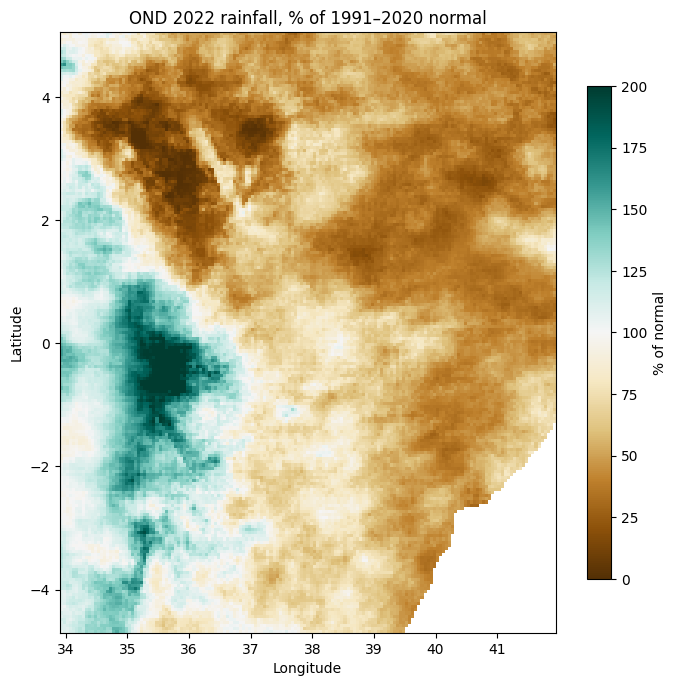

In [7]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

with rasterio.open("ond2022_percent_of_normal.tif") as src:
    pct = src.read(1)
    b = src.bounds
    if src.nodata is not None:
        pct = np.where(pct == src.nodata, np.nan, pct)

fig, ax = plt.subplots(figsize=(8, 8))
img = ax.imshow(pct, extent=[b.left, b.right, b.bottom, b.top], cmap="BrBG", vmin=0, vmax=200)
ax.set_title("OND 2022 rainfall, % of 1991–2020 normal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.colorbar(img, ax=ax, label="% of normal", shrink=0.8)
plt.show()

## 6. Classify Drought Severity

Nested `if` and `lt` processes inside `apply` turn percent of normal into classes 0–3. Each `if` returns its second argument when the condition is true, otherwise its third.

In [8]:
severity = percent_of_normal.apply(
    lambda x: P.if_(P.lt(x, 50), 3,
              P.if_(P.lt(x, 75), 2,
              P.if_(P.lt(x, 90), 1, 0)))
)

severity.download("ond2022_severity.tif", format="GTiff")
print("Severity classes downloaded.")

Severity classes downloaded.


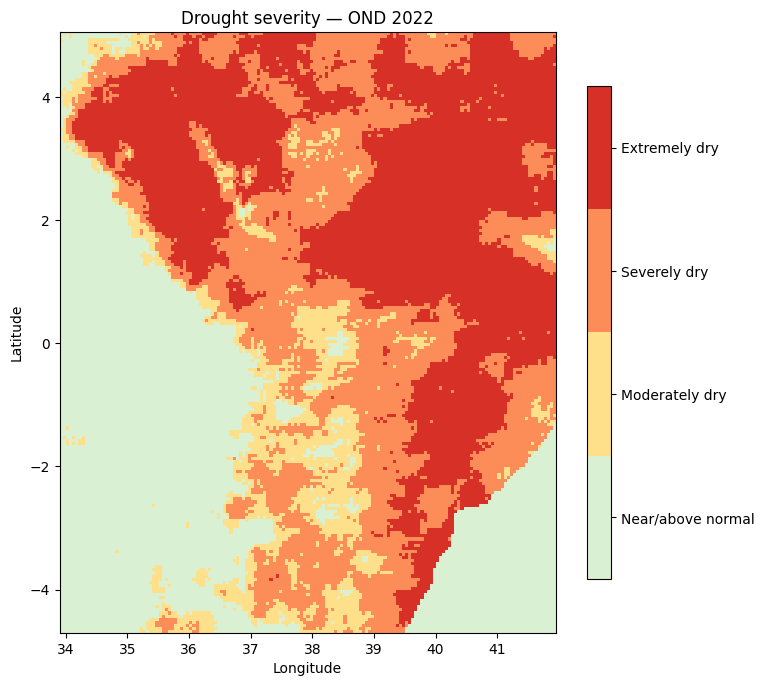

In [9]:
from matplotlib.colors import ListedColormap

CLASS_NAMES = ["Near/above normal", "Moderately dry", "Severely dry", "Extremely dry"]

with rasterio.open("ond2022_severity.tif") as src:
    sev = src.read(1).astype(float)
    b = src.bounds
    if src.nodata is not None:
        sev[sev == src.nodata] = np.nan

fig, ax = plt.subplots(figsize=(8, 8))
cmap = ListedColormap(["#d9f0d3", "#fee08b", "#fc8d59", "#d73027"])
img = ax.imshow(sev, extent=[b.left, b.right, b.bottom, b.top], cmap=cmap,
                vmin=-0.5, vmax=3.5, interpolation="nearest")
cbar = plt.colorbar(img, ax=ax, ticks=[0, 1, 2, 3], shrink=0.8)
cbar.ax.set_yticklabels(CLASS_NAMES)
ax.set_title("Drought severity — OND 2022")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

## 7. Rank Counties with `zonal_stats`

Aggregate percent of normal per county. Feature properties (here `county`) are carried through to the result, so each row is labelled.

In [10]:
import pandas as pd

county_stats = percent_of_normal.process(
    "zonal_stats",
    data_cube=percent_of_normal,
    geometries=counties,
    stats=["mean", "min", "max"],
)

records = json.loads(county_stats.save_result(format="JSON").download())
df = (
    pd.DataFrame(records)
    .pivot_table(index="county", columns="variable", values="value")
    [["mean", "min", "max"]]
    .sort_values("mean")
)
df["class"] = pd.cut(df["mean"], [-np.inf, 50, 75, 90, np.inf], right=False,
                     labels=CLASS_NAMES[::-1])
print(df.head(10).round(1).to_string())

variable    mean   min    max          class
county                                      
Turkana     35.9   0.0  116.6  Extremely dry
Mandera     36.5  14.9   54.5  Extremely dry
Wajir       36.9  17.6   69.1  Extremely dry
Mombasa     48.5  44.0   57.2  Extremely dry
Isiolo      49.5  16.0  105.2  Extremely dry
Marsabit    49.6   1.0   98.3  Extremely dry
Garissa     50.3  28.0   85.8   Severely dry
Kilifi      50.8  31.7   84.0   Severely dry
Lamu        55.1  32.9   80.8   Severely dry
Tana River  55.2  28.0  105.2   Severely dry


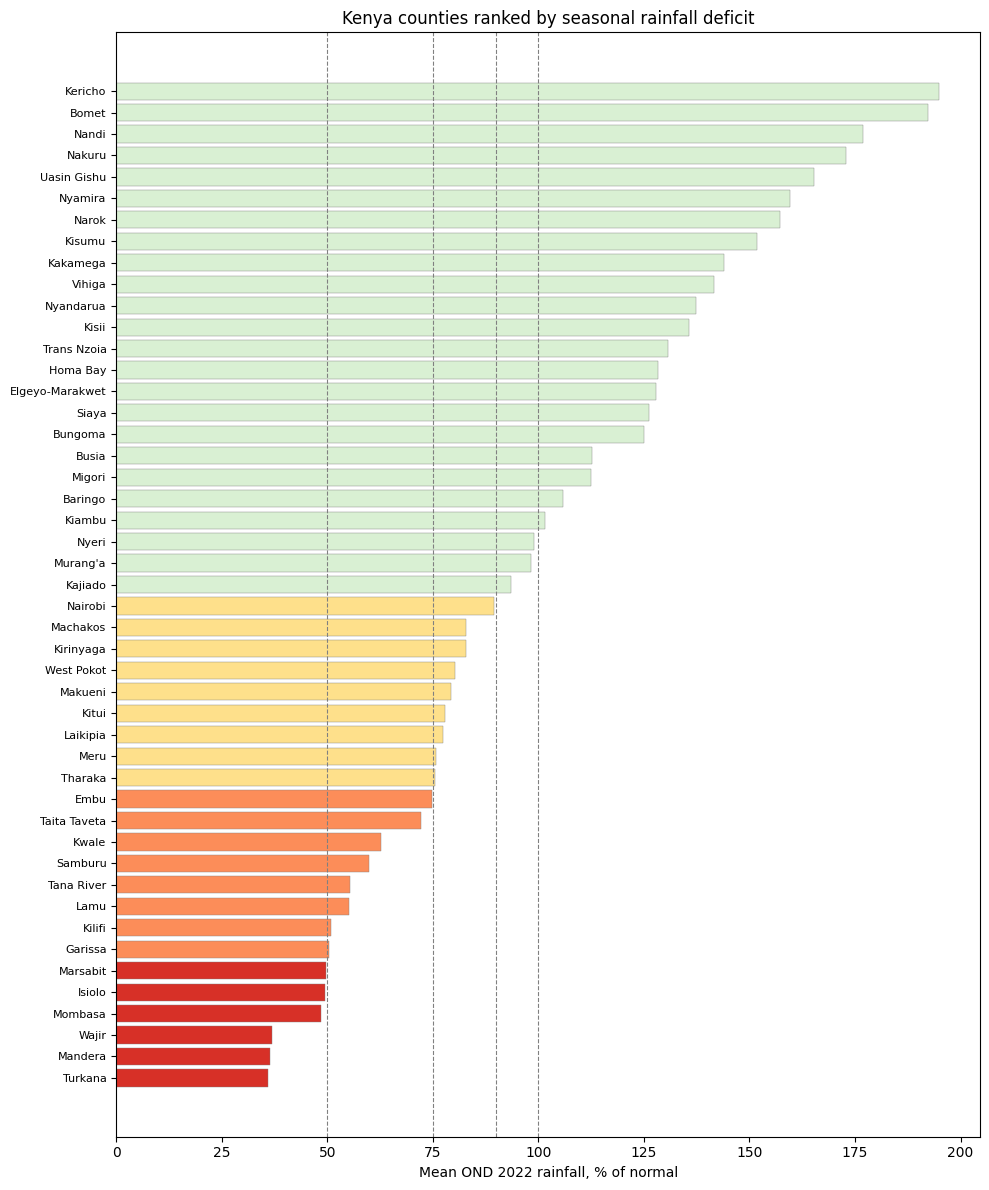

In [11]:
fig, ax = plt.subplots(figsize=(10, 12))
colors = df["class"].map(dict(zip(CLASS_NAMES, ["#d9f0d3", "#fee08b", "#fc8d59", "#d73027"])))
ax.barh(df.index, df["mean"], color=colors, edgecolor="grey", linewidth=0.3)
for x in (50, 75, 90, 100):
    ax.axvline(x, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Mean OND 2022 rainfall, % of normal")
ax.set_title("Kenya counties ranked by seasonal rainfall deficit")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## 8. Export to CSV

The same graph can return CSV directly, ready for spreadsheets or reporting tools.

In [12]:
county_stats.save_result(format="CSV").download("ond2022_county_drought.csv")
print(pd.read_csv("ond2022_county_drought.csv").head())

     geometry  spatial_ref variable      value      county
0  geometry_0            0     mean  35.949612     Turkana
1  geometry_1            0     mean  49.568731    Marsabit
2  geometry_2            0     mean  36.490654     Mandera
3  geometry_3            0     mean  36.941607       Wajir
4  geometry_4            0     mean  80.305542  West Pokot


## 9. Inspect the Process Graph

Everything above runs on the server as a single openEO process graph. You can print it as JSON and paste it into the [Web Editor](https://data.fao.org/editor/?server=data.fao.org%2Fopeneo) to run or modify it without code.

In [13]:
graph = county_stats.save_result(format="CSV").flat_graph()
print(f"{len(graph)} nodes: {', '.join(n['process_id'] for n in graph.values())}")

10 nodes: load_collection, reduce_dimension, load_collection, climatological_normal, filter_labels, reduce_dimension, merge_cubes, apply, zonal_stats, save_result


## Summary

In this tutorial, you learned how to:

1. **Compute a climatological normal** with `climatological_normal`
2. **Select months by label** with `filter_labels`
3. **Compute percent of normal** with cube arithmetic
4. **Classify severity** with nested `if`/`lt` inside `apply`
5. **Rank counties** with `zonal_stats` and export the table as CSV

### Try It Yourself

- Change the season to March–May (long rains): labels `"03"`, `"04"`, `"05"`
- Use another region and boundary file
- Repeat with a vegetation index such as `fao-gismgr:ASIS:raster:mapsets:VHI-M`

### Related Tutorials

- **[Zonal Statistics](03_zonal_statistics.ipynb)** — More on `zonal_stats` options
- **[Data Cube Operations](06_data_cube_operations.ipynb)** — Filtering, arithmetic, masking